# Module specificity: are cells module-attributable, or equally predictive of every module?

Companion to `grid_module_functional_clusters.ipynb`. That notebook asked
"can grid cells/modules be *clustered* out of the coupling graph" (answer:
not reliably — Leiden found essentially no structure beyond a single
dominant blob). This notebook asks a more direct, better-posed question:

> **For a given cell, is its pairwise-XGBoost coupling to module-0 grid cells
> different from its coupling to module-1 grid cells (module-*specific*), or
> are the two roughly equal (equally predictive of every module)?**

This sidesteps clustering entirely — no algorithm has to "discover" how many
groups exist. It's tested identically for grid cells and non-grid cells,
using each cell's own coupling profile.

## Method

For every cell *i* (grid or non-grid) in a session:

- `m0` = mean Δ pR² (or raw pR²) between cell *i* and module-0 grid cells
- `m1` = mean Δ pR² (or raw pR²) between cell *i* and module-1 grid cells
- **specificity margin** = `|m0 - m1|` — near 0 means "equally predictive of
  both modules"; large means module-specific
- **significance**: permutation null built by shuffling which grid cells
  carry module label 0 vs 1 (group sizes preserved), recomputing the margin
  each time — gives a per-cell p-value under "no true module-specific
  coupling"
- when cell *i* is itself a labelled grid cell, it is excluded from its own
  module's average (a naive average would count its zero self-coupling as a
  real data point and bias its own-module mean down, worst for the
  minority module)
- **multiple-comparisons correction**: with ~100-280 cells tested per
  session, uncorrected p<0.05 alone would flag ~5-14 cells by chance. All
  significance calls below use Benjamini-Hochberg FDR (q<0.05). This is a
  necessary correction the earlier notebook's uncorrected per-cell counts
  were missing.
- `N_PERM=10000` — needed so the permutation p-value floor (`1/(N_PERM+1)`)
  is well below the smallest FDR-survivable p-value for the largest session
  (~280 cells, BH rank-1 threshold ≈ 0.05/280 ≈ 0.00018).

Run for both **raw pR²** (baseline='null', includes shared tuning) and
**Δ pR²** (richest behavioural baseline, tuning removed), and pooled across
the same three sessions used previously (M26D19 VR+OF1, M25D25 OF1,
M21D26 OF1) for the population-level estimate.

In [1]:
import numpy as np
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

%load_ext autoreload
%autoreload 2
%matplotlib inline
plt.rcParams['font.family'] = 'Arial'

DATA_PATH = '/Users/harryclark/Documents/spatial-manifolds/data/eddie/xgboost_pairwise/'
CC_PATH   = '/Users/harryclark/Documents/spatial-manifolds/data/cell_classifications.csv'
FIG_PATH  = '/Users/harryclark/Documents/spatial-manifolds/scripts/figures/figure_playground/module_specificity/'
os.makedirs(FIG_PATH, exist_ok=True)

HISTORY_LENGTH = 100  # matches the cached pairwise CSVs (h100)

SESSIONS = [
    dict(mouse=26, day=19, sessions=['VR', 'OF1']),
    dict(mouse=25, day=25, sessions=['OF1']),
    dict(mouse=21, day=26, sessions=['OF1']),
]

RICH_BASELINE = {'VR': 'pos_speed_lfp', 'OF1': 'pos_speed_hd_hing_lfp'}
RAW_BASELINE  = 'null'
METRICS = [('raw', RAW_BASELINE), ('delta', None)]  # 'delta' baseline resolved per session_type below

N_PERM   = 10000
RNG_SEED = 42
FDR_Q    = 0.05

GROUP_COLORS = {
    'Module 0 (GC)':    '#c0392b',
    'Module 1 (GC)':    '#2980b9',
    'GC (unassigned)':  '#8e44ad',
    'Non-grid spatial': '#27ae60',
    'Other':            '#7f8c8d',
}
GROUP_ORDER = list(GROUP_COLORS.keys())

## 1. Load grid-module ground truth and pairwise-assay results

In [2]:
cc = pd.read_csv(CC_PATH, low_memory=False)
cc['mouse']      = cc['mouse'].astype(int)
cc['day']        = cc['day'].astype(int)
cc['cluster_id'] = cc['cluster_id'].astype(int)


def get_module_labels(mouse, day):
    sub = cc[(cc.mouse == mouse) & (cc.day == day)].drop_duplicates('cluster_id')
    out = {}
    for _, r in sub.iterrows():
        mod = int(r['grid_module']) if pd.notna(r['grid_module']) else -1
        out[int(r['cluster_id'])] = dict(cell_type=r['cell_type'], module=mod)
    return out


def cell_group(cid, mod_labels):
    info = mod_labels.get(cid, dict(cell_type='Other', module=-1))
    if info['cell_type'] == 'GC' and info['module'] == 0:
        return 'Module 0 (GC)'
    if info['cell_type'] == 'GC' and info['module'] == 1:
        return 'Module 1 (GC)'
    if info['cell_type'] == 'GC':
        return 'GC (unassigned)'
    if info['cell_type'] == 'NG':
        return 'Non-grid spatial'
    return 'Other'


def load_pairwise(mouse, day, session_type, history_length=HISTORY_LENGTH, data_path=DATA_PATH):
    pattern = os.path.join(data_path, f'xgboost_pairwise_M{mouse}_D{day}_h{history_length}_{session_type}_*.csv')
    files = sorted(glob.glob(pattern))
    if not files:
        return None
    # keep_default_na=False: pandas' default NA sniffing treats the literal
    # string "null" (one of our baseline names) as a missing value otherwise.
    df = pd.concat([pd.read_csv(f, keep_default_na=False) for f in files], ignore_index=True)
    return df

## 2. Build the pR² matrices (raw and Δ, same construction as the clustering notebook)

In [3]:
def build_pr2_matrix(pw_df, baseline):
    bl = (pw_df[(pw_df.baseline == baseline) & (pw_df.covariate_cluster_id == -1)]
          [['target_cluster_id', 'pR2_cv']].rename(columns={'pR2_cv': 'pR2_baseline'})
          .drop_duplicates('target_cluster_id'))
    cv = (pw_df[(pw_df.baseline == baseline) & (pw_df.covariate_cluster_id >= 0)]
          [['target_cluster_id', 'covariate_cluster_id', 'pR2_cv']].copy())
    merged = cv.merge(bl, on='target_cluster_id', how='inner')
    merged['d'] = merged['pR2_cv'] - merged['pR2_baseline']

    all_ids = sorted(set(merged.target_cluster_id) | set(merged.covariate_cluster_id))
    idx = {cid: i for i, cid in enumerate(all_ids)}
    N = len(all_ids)
    mat = np.full((N, N), np.nan)
    for row in merged.itertuples(index=False):
        i = idx[int(row.covariate_cluster_id)]
        j = idx[int(row.target_cluster_id)]
        mat[i, j] = row.d
    np.fill_diagonal(mat, 0)
    sym = np.nanmean(np.stack([mat, mat.T]), axis=0)
    sym = np.nan_to_num(sym, nan=0.0)
    return sym, all_ids


def build_session_matrices(pw_df, session_type):
    rich = RICH_BASELINE[session_type]
    for b in (RAW_BASELINE, rich):
        if b not in pw_df['baseline'].unique():
            raise ValueError(f'baseline "{b}" not found in this session pairwise CSVs')
    raw_sym, ids_raw = build_pr2_matrix(pw_df, RAW_BASELINE)
    delta_sym, ids_delta = build_pr2_matrix(pw_df, rich)
    assert ids_raw == ids_delta, 'cell id sets differ between baselines -- unexpected'
    return dict(raw=raw_sym, delta=delta_sym), ids_raw

## 3. Module-specificity index + permutation test + BH-FDR

`compute_module_specificity` returns one row per cell with `m0`, `m1`, the
specificity margin, and a permutation p-value — computed identically for
grid and non-grid cells (grid cells get self-excluded from their own
module's average; see markdown above).

In [4]:
def bh_fdr(pvals):
    '''Benjamini-Hochberg FDR. Returns q-values aligned with input order.'''
    pvals = np.asarray(pvals, dtype=float)
    n = len(pvals)
    order = np.argsort(pvals)
    ranked = pvals[order]
    q = ranked * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    out = np.empty(n)
    out[order] = q
    return out


def compute_module_specificity(sym_mat, cell_ids, mod_labels, n_perm=N_PERM, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    gc_idx = [i for i, cid in enumerate(cell_ids)
             if mod_labels.get(cid, {}).get('cell_type') == 'GC'
             and mod_labels.get(cid, {}).get('module', -1) in (0, 1)]
    if len(gc_idx) < 6:
        return None
    n = len(cell_ids)
    true_labels = np.array([mod_labels[cell_ids[i]]['module'] for i in gc_idx])

    sub = sym_mat[:, gc_idx]  # (n, n_gc) -- every cell's coupling to every labelled grid cell

    gc_pos_of = -np.ones(n, dtype=int)  # row i's position within gc_idx, or -1 if not a labelled GC
    for pos, gi in enumerate(gc_idx):
        gc_pos_of[gi] = pos

    def margins(lab):
        is0 = (lab == 0)
        S0 = sub[:, is0].sum(axis=1)
        S1 = sub[:, ~is0].sum(axis=1)
        n0, n1 = int(is0.sum()), int((~is0).sum())
        own_lab = np.where(gc_pos_of >= 0, lab[np.clip(gc_pos_of, 0, len(lab) - 1)], -1)
        denom0 = np.maximum(np.where(own_lab == 0, n0 - 1, n0), 1)
        denom1 = np.maximum(np.where(own_lab == 1, n1 - 1, n1), 1)
        return S0 / denom0, S1 / denom1

    m0_obs, m1_obs = margins(true_labels)
    margin_obs = np.abs(m0_obs - m1_obs)

    null_margins = np.empty((n_perm, n))
    for k in range(n_perm):
        m0p, m1p = margins(rng.permutation(true_labels))
        null_margins[k] = np.abs(m0p - m1p)

    p = (np.sum(null_margins >= margin_obs[None, :], axis=0) + 1) / (n_perm + 1)
    q = bh_fdr(p)

    true_module = np.array([mod_labels.get(cid, {}).get('module', -1) for cid in cell_ids])
    df = pd.DataFrame({
        'cluster_id':        cell_ids,
        'cell_type':         [mod_labels.get(cid, {}).get('cell_type', 'Other') for cid in cell_ids],
        'group':             [cell_group(cid, mod_labels) for cid in cell_ids],
        'true_module':       true_module,
        'mean_to_module0':   m0_obs,
        'mean_to_module1':   m1_obs,
        'margin':            margin_obs,
        'p_value':           p,
        'q_value':           q,
        'significant':       q < FDR_Q,
    })
    df['preferred_module'] = np.where(df['mean_to_module0'] > df['mean_to_module1'], 0, 1)
    return df

## 4. Run for every session, both metrics (raw pR² and Δ pR²)

In [5]:
results = {}  # (mouse, day, session_type, metric) -> specificity dataframe

for cfg in SESSIONS:
    mouse, day = cfg['mouse'], cfg['day']
    mod_labels = get_module_labels(mouse, day)

    for session_type in cfg['sessions']:
        print(f'\n===== M{mouse} D{day} {session_type} =====')
        pw = load_pairwise(mouse, day, session_type)
        if pw is None:
            print('  no pairwise CSVs found, skipping')
            continue
        mats, cell_ids = build_session_matrices(pw, session_type)

        for metric in ('raw', 'delta'):
            df = compute_module_specificity(mats[metric], cell_ids, mod_labels)
            if df is None:
                print(f'  [{metric}] not enough labelled grid cells, skipping')
                continue
            results[(mouse, day, session_type, metric)] = df

            n_sig = df['significant'].sum()
            n_tot = len(df)
            expected_by_chance = 0.05 * n_tot
            by_group = df.groupby('group')['significant'].agg(['sum', 'count'])
            print(f'  [{metric}] {n_sig}/{n_tot} cells FDR-significant '
                  f'(uncorrected-chance expectation ~{expected_by_chance:.0f})')
            for g in GROUP_ORDER:
                if g in by_group.index:
                    s, c = by_group.loc[g, 'sum'], by_group.loc[g, 'count']
                    print(f'      {g:<18s}: {int(s):3d}/{int(c):3d}  ({100*s/c:.0f}%)')

        # sanity check: do module-0/module-1 grid cells get correctly assigned to
        # THEIR OWN true module by the sign of (m0 - m1)?
        df_delta = results.get((mouse, day, session_type, 'delta'))
        if df_delta is not None:
            gc = df_delta[df_delta['true_module'].isin([0, 1])]
            correct = (gc['preferred_module'] == gc['true_module']).mean()
            print(f'  [delta] positive control: {100*correct:.0f}% of labelled grid cells '
                  f'preferentially predicted by their OWN true module')


===== M26 D19 VR =====


  [raw] 0/280 cells FDR-significant (uncorrected-chance expectation ~14)
      Module 0 (GC)     :   0/ 38  (0%)
      Module 1 (GC)     :   0/  3  (0%)
      GC (unassigned)   :   0/  6  (0%)
      Non-grid spatial  :   0/213  (0%)
      Other             :   0/ 20  (0%)


  [delta] 0/280 cells FDR-significant (uncorrected-chance expectation ~14)
      Module 0 (GC)     :   0/ 38  (0%)
      Module 1 (GC)     :   0/  3  (0%)
      GC (unassigned)   :   0/  6  (0%)
      Non-grid spatial  :   0/213  (0%)
      Other             :   0/ 20  (0%)
  [delta] positive control: 85% of labelled grid cells preferentially predicted by their OWN true module

===== M26 D19 OF1 =====


  [raw] 0/280 cells FDR-significant (uncorrected-chance expectation ~14)
      Module 0 (GC)     :   0/ 38  (0%)
      Module 1 (GC)     :   0/  3  (0%)
      GC (unassigned)   :   0/  6  (0%)
      Non-grid spatial  :   0/213  (0%)
      Other             :   0/ 20  (0%)


  [delta] 0/280 cells FDR-significant (uncorrected-chance expectation ~14)
      Module 0 (GC)     :   0/ 38  (0%)
      Module 1 (GC)     :   0/  3  (0%)
      GC (unassigned)   :   0/  6  (0%)
      Non-grid spatial  :   0/213  (0%)
      Other             :   0/ 20  (0%)
  [delta] positive control: 85% of labelled grid cells preferentially predicted by their OWN true module

===== M25 D25 OF1 =====


  [raw] 0/108 cells FDR-significant (uncorrected-chance expectation ~5)
      Module 0 (GC)     :   0/ 35  (0%)
      Module 1 (GC)     :   0/  7  (0%)
      GC (unassigned)   :   0/  2  (0%)
      Non-grid spatial  :   0/ 49  (0%)
      Other             :   0/ 15  (0%)


  [delta] 0/108 cells FDR-significant (uncorrected-chance expectation ~5)
      Module 0 (GC)     :   0/ 35  (0%)
      Module 1 (GC)     :   0/  7  (0%)
      GC (unassigned)   :   0/  2  (0%)
      Non-grid spatial  :   0/ 49  (0%)
      Other             :   0/ 15  (0%)
  [delta] positive control: 79% of labelled grid cells preferentially predicted by their OWN true module

===== M21 D26 OF1 =====


  [raw] 1/147 cells FDR-significant (uncorrected-chance expectation ~7)
      Module 0 (GC)     :   1/  8  (12%)
      Module 1 (GC)     :   0/ 20  (0%)
      GC (unassigned)   :   0/  4  (0%)
      Non-grid spatial  :   0/107  (0%)
      Other             :   0/  8  (0%)


  [delta] 0/147 cells FDR-significant (uncorrected-chance expectation ~7)
      Module 0 (GC)     :   0/  8  (0%)
      Module 1 (GC)     :   0/ 20  (0%)
      GC (unassigned)   :   0/  4  (0%)
      Non-grid spatial  :   0/107  (0%)
      Other             :   0/  8  (0%)
  [delta] positive control: 79% of labelled grid cells preferentially predicted by their OWN true module


## 5. Example-session visualisations

For each example session: **left** — every cell's mean coupling to module-0
vs module-1 grid cells (the dashed line is "equally predictive of both
modules"; points off the line are module-specific; outlined markers are
FDR-significant). **right** — the same data as a volcano plot (margin vs
significance), with the BH cutoff drawn as a horizontal line.

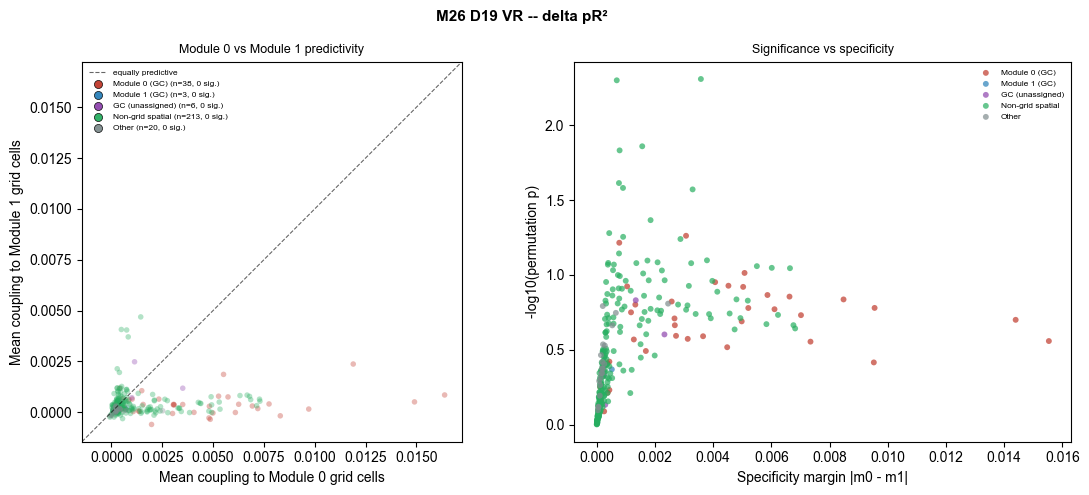

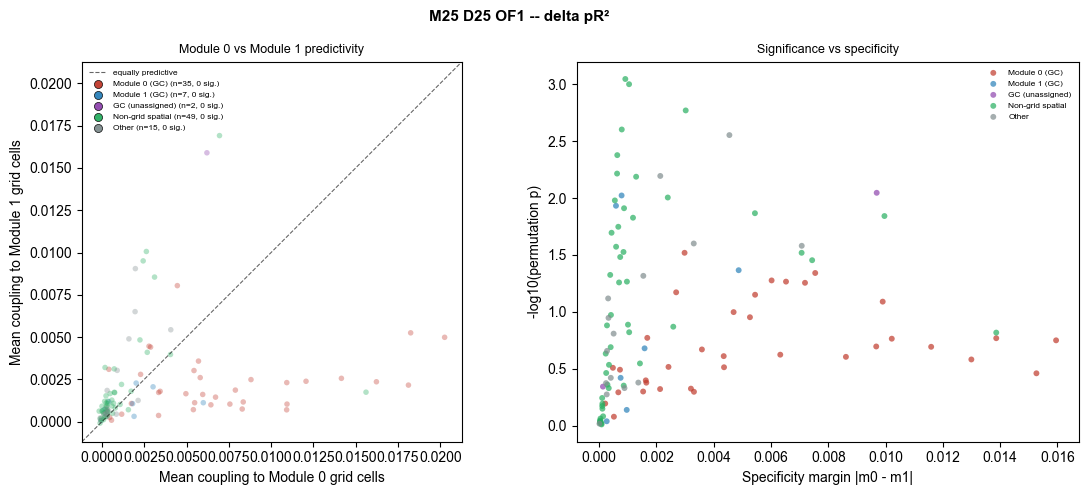

In [6]:
def plot_specificity(df, title):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))

    ax = axes[0]
    lo = min(df['mean_to_module0'].min(), df['mean_to_module1'].min())
    hi = max(df['mean_to_module0'].max(), df['mean_to_module1'].max())
    pad = 0.05 * (hi - lo + 1e-9)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], 'k--', lw=0.8, alpha=0.6,
           label='equally predictive')
    for g in GROUP_ORDER:
        sub = df[df['group'] == g]
        if len(sub) == 0:
            continue
        ns, sig = sub[~sub['significant']], sub[sub['significant']]
        ax.scatter(ns['mean_to_module0'], ns['mean_to_module1'], s=16,
                  color=GROUP_COLORS[g], alpha=0.35, edgecolors='none')
        ax.scatter(sig['mean_to_module0'], sig['mean_to_module1'], s=34,
                  color=GROUP_COLORS[g], alpha=0.95, edgecolors='k', linewidths=0.5,
                  label=f'{g} (n={len(sub)}, {sig.shape[0]} sig.)')
    ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlabel('Mean coupling to Module 0 grid cells')
    ax.set_ylabel('Mean coupling to Module 1 grid cells')
    ax.set_title('Module 0 vs Module 1 predictivity', fontsize=9)
    ax.legend(fontsize=6, frameon=False, loc='upper left')
    ax.set_aspect('equal', adjustable='box')

    ax = axes[1]
    for g in GROUP_ORDER:
        sub = df[df['group'] == g]
        if len(sub) == 0:
            continue
        ax.scatter(sub['margin'], -np.log10(sub['p_value']), s=18,
                  color=GROUP_COLORS[g], alpha=0.7, edgecolors='none', label=g)
    if df['significant'].any():
        p_cutoff = df.loc[df['significant'], 'p_value'].max()
        ax.axhline(-np.log10(p_cutoff), color='k', ls='--', lw=0.8,
                  label=f'BH q<{FDR_Q} cutoff')
    ax.set_xlabel('Specificity margin |m0 - m1|')
    ax.set_ylabel('-log10(permutation p)')
    ax.set_title('Significance vs specificity', fontsize=9)
    ax.legend(fontsize=6, frameon=False)

    fig.suptitle(title, fontsize=11, fontweight='bold')
    plt.tight_layout()
    return fig


example_keys = [
    (26, 19, 'VR', 'delta'),
    (25, 25, 'OF1', 'delta'),
]
for mouse, day, session_type, metric in example_keys:
    df = results.get((mouse, day, session_type, metric))
    if df is None:
        continue
    fig = plot_specificity(df, f'M{mouse} D{day} {session_type} -- {metric} pR²')
    fig.savefig(os.path.join(FIG_PATH, f'specificity_M{mouse}D{day}_{session_type}_{metric}.pdf'),
               dpi=200, bbox_inches='tight')
    plt.show()

## 6. Population summary (pooled across all sessions)

The question this notebook was built to answer: pooling every cell from
every session/type combo, what fraction of grid cells vs non-grid-spatial
cells vs other cells are FDR-significantly module-specific, vs equally
predictive of both modules?

In [7]:
pooled_rows = []
for (mouse, day, session_type, metric), df in results.items():
    d = df.copy()
    d['mouse'] = mouse; d['day'] = day; d['session_type'] = session_type; d['metric'] = metric
    pooled_rows.append(d)
pooled = pd.concat(pooled_rows, ignore_index=True)
pooled.to_csv(os.path.join(FIG_PATH, 'module_specificity_pooled.csv'), index=False)

summary = (pooled.groupby(['metric', 'group'])['significant']
          .agg(n_significant='sum', n_total='count')
          .reset_index())
summary['pct_significant'] = 100 * summary['n_significant'] / summary['n_total']
summary

,metric,group,n_significant,n_total,pct_significant
0,delta,GC (unassigned),0,18,0.000000
1,delta,Module 0 (GC),0,119,0.000000
2,delta,Module 1 (GC),0,33,0.000000
3,delta,Non-grid spatial,0,582,0.000000
4,delta,Other,0,63,0.000000
5,raw,GC (unassigned),0,18,0.000000
6,raw,Module 0 (GC),1,119,0.840336
7,raw,Module 1 (GC),0,33,0.000000
8,raw,Non-grid spatial,0,582,0.000000
9,raw,Other,0,63,0.000000


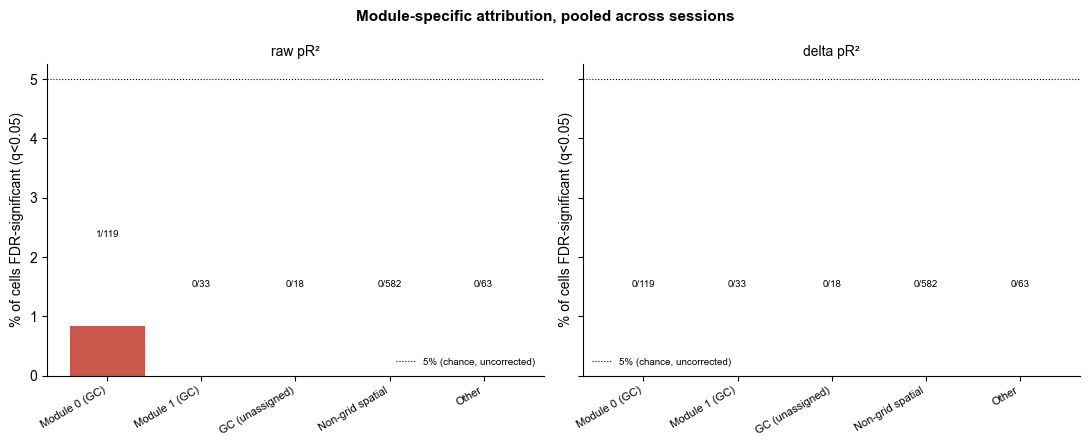

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, metric in zip(axes, ['raw', 'delta']):
    sub = summary[summary['metric'] == metric].set_index('group').reindex(GROUP_ORDER).dropna(how='all')
    x = np.arange(len(sub))
    bars = ax.bar(x, sub['pct_significant'], color=[GROUP_COLORS[g] for g in sub.index], alpha=0.85)
    for xi, (n_sig, n_tot) in zip(x, zip(sub['n_significant'].astype(int), sub['n_total'].astype(int))):
        ax.text(xi, sub['pct_significant'].iloc[xi] + 1.5, f'{n_sig}/{n_tot}',
               ha='center', fontsize=7)
    ax.axhline(5, color='k', ls=':', lw=0.8, label='5% (chance, uncorrected)')
    ax.set_xticks(x); ax.set_xticklabels(sub.index, rotation=30, ha='right', fontsize=8)
    ax.set_title(f'{metric} pR²', fontsize=10)
    ax.set_ylabel('% of cells FDR-significant (q<0.05)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(fontsize=7, frameon=False)
fig.suptitle('Module-specific attribution, pooled across sessions', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, 'population_pct_significant.pdf'), dpi=200, bbox_inches='tight')
plt.show()

Effect size (not just significance): pooled margin distribution by group.

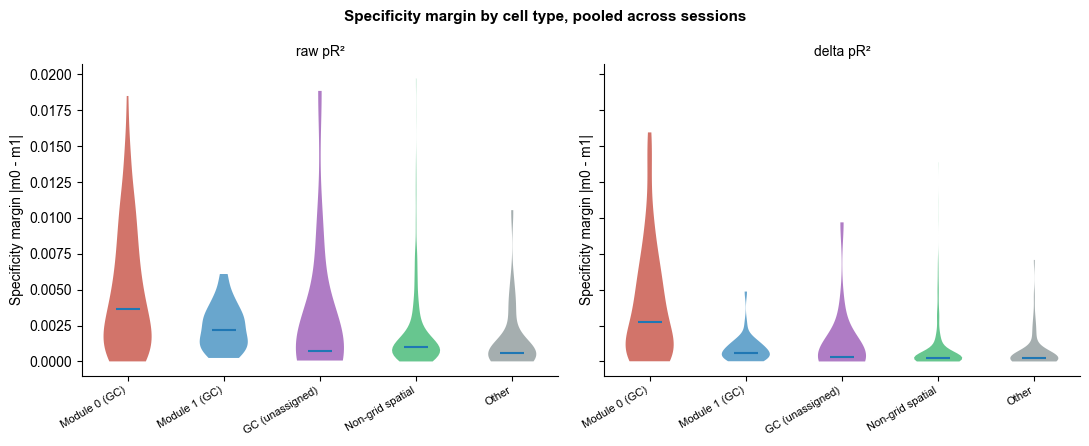

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, metric in zip(axes, ['raw', 'delta']):
    sub = pooled[pooled['metric'] == metric]
    data = [sub[sub['group'] == g]['margin'].values for g in GROUP_ORDER]
    data = [d for d in data if len(d) > 0]
    labels = [g for g in GROUP_ORDER if len(sub[sub['group'] == g]) > 0]
    parts = ax.violinplot(data, showmedians=True, showextrema=False)
    for pc, g in zip(parts['bodies'], labels):
        pc.set_facecolor(GROUP_COLORS[g]); pc.set_alpha(0.7)
    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=8)
    ax.set_title(f'{metric} pR²', fontsize=10)
    ax.set_ylabel('Specificity margin |m0 - m1|')
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Specificity margin by cell type, pooled across sessions', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, 'population_margin_distribution.pdf'), dpi=200, bbox_inches='tight')
plt.show()

## 7. Bottom line

In [10]:
for metric in ('raw', 'delta'):
    print(f'--- {metric} pR² ---')
    sub = summary[summary['metric'] == metric]
    for _, row in sub.iterrows():
        verdict = 'module-attributable' if row['pct_significant'] > 10 else 'mostly equally predictive'
        print(f"  {row['group']:<18s}: {row['pct_significant']:5.1f}% significant "
              f"({int(row['n_significant'])}/{int(row['n_total'])})  -- {verdict}")
    print()

--- raw pR² ---
  GC (unassigned)   :   0.0% significant (0/18)  -- mostly equally predictive
  Module 0 (GC)     :   0.8% significant (1/119)  -- mostly equally predictive
  Module 1 (GC)     :   0.0% significant (0/33)  -- mostly equally predictive
  Non-grid spatial  :   0.0% significant (0/582)  -- mostly equally predictive
  Other             :   0.0% significant (0/63)  -- mostly equally predictive

--- delta pR² ---
  GC (unassigned)   :   0.0% significant (0/18)  -- mostly equally predictive
  Module 0 (GC)     :   0.0% significant (0/119)  -- mostly equally predictive
  Module 1 (GC)     :   0.0% significant (0/33)  -- mostly equally predictive
  Non-grid spatial  :   0.0% significant (0/582)  -- mostly equally predictive
  Other             :   0.0% significant (0/63)  -- mostly equally predictive

